# Q1. Camera &nbsp;&nbsp;&nbsp; 5 x 5 = 25 points

**(a)** In the Assignment 1, Q1, find the coordinates of the centre of the swinging load,
$o_1(x, y, z)$ for all frames in training set rgb_train_val_swingingload.avi. Use the $M_{int}$
obtained in the Lab. Plot the 3D coordinates of swinging load for all frames.

**(b)** Say, the default intrinsic matrix of L515 is

$$M_d = \begin{bmatrix} 1342 & 0 & 325 \\ 0 & 1342 & 235 \\ 0 & 0 & 1 \end{bmatrix}$$

Use this matrix to find the 3D coordinates of the center of swinging load for all frames ($o_2$)
and plot them.

**(c)** Which intrinsic matrix - $M_{int}$ or $M_d$ is accurate? Give reasons for your answers.

**(d)** From the data set obtained from (a) and (b) i.e. $o_1$ and $o_2$. Implement ML model that
learns the function parameters such that $f_\theta(o_1) = o_2^*$. Explain the results by
finding/demonstrating the relevant KPIs.

**(e)** Find the Euclidean error between (i) $o_1$ and $o_2$ and (ii) $o_1$ and $o_2^*$. Make the
interpretations of the results that you obtain.

---

$ python main.py   (in /home/havard/hand_in/MAS512_Assignment_2/q1)


  /home/havard/hand_in/MAS512_Assignment_2/q1/main.py:138: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


    plt.show()


  (c) M_int: field of view 56.0 x 43.5 deg


  (c) M_d: field of view 26.8 x 20.3 deg


...

      KPIs on test set: RMSE [mm] = 0.001370, MAE [mm] = 0.000794, R2 = 1.000000


  (e) (i)  |o1 - o2|:  mean 255.46 mm, max 349.39 mm


      (ii) |o1 - o2*|: mean 255.46 mm, max 349.39 mm


  [exit 0, 121 s]


**Q1 (a) (b) - centre of the load with M_int (o1) and with M_d (o2)**

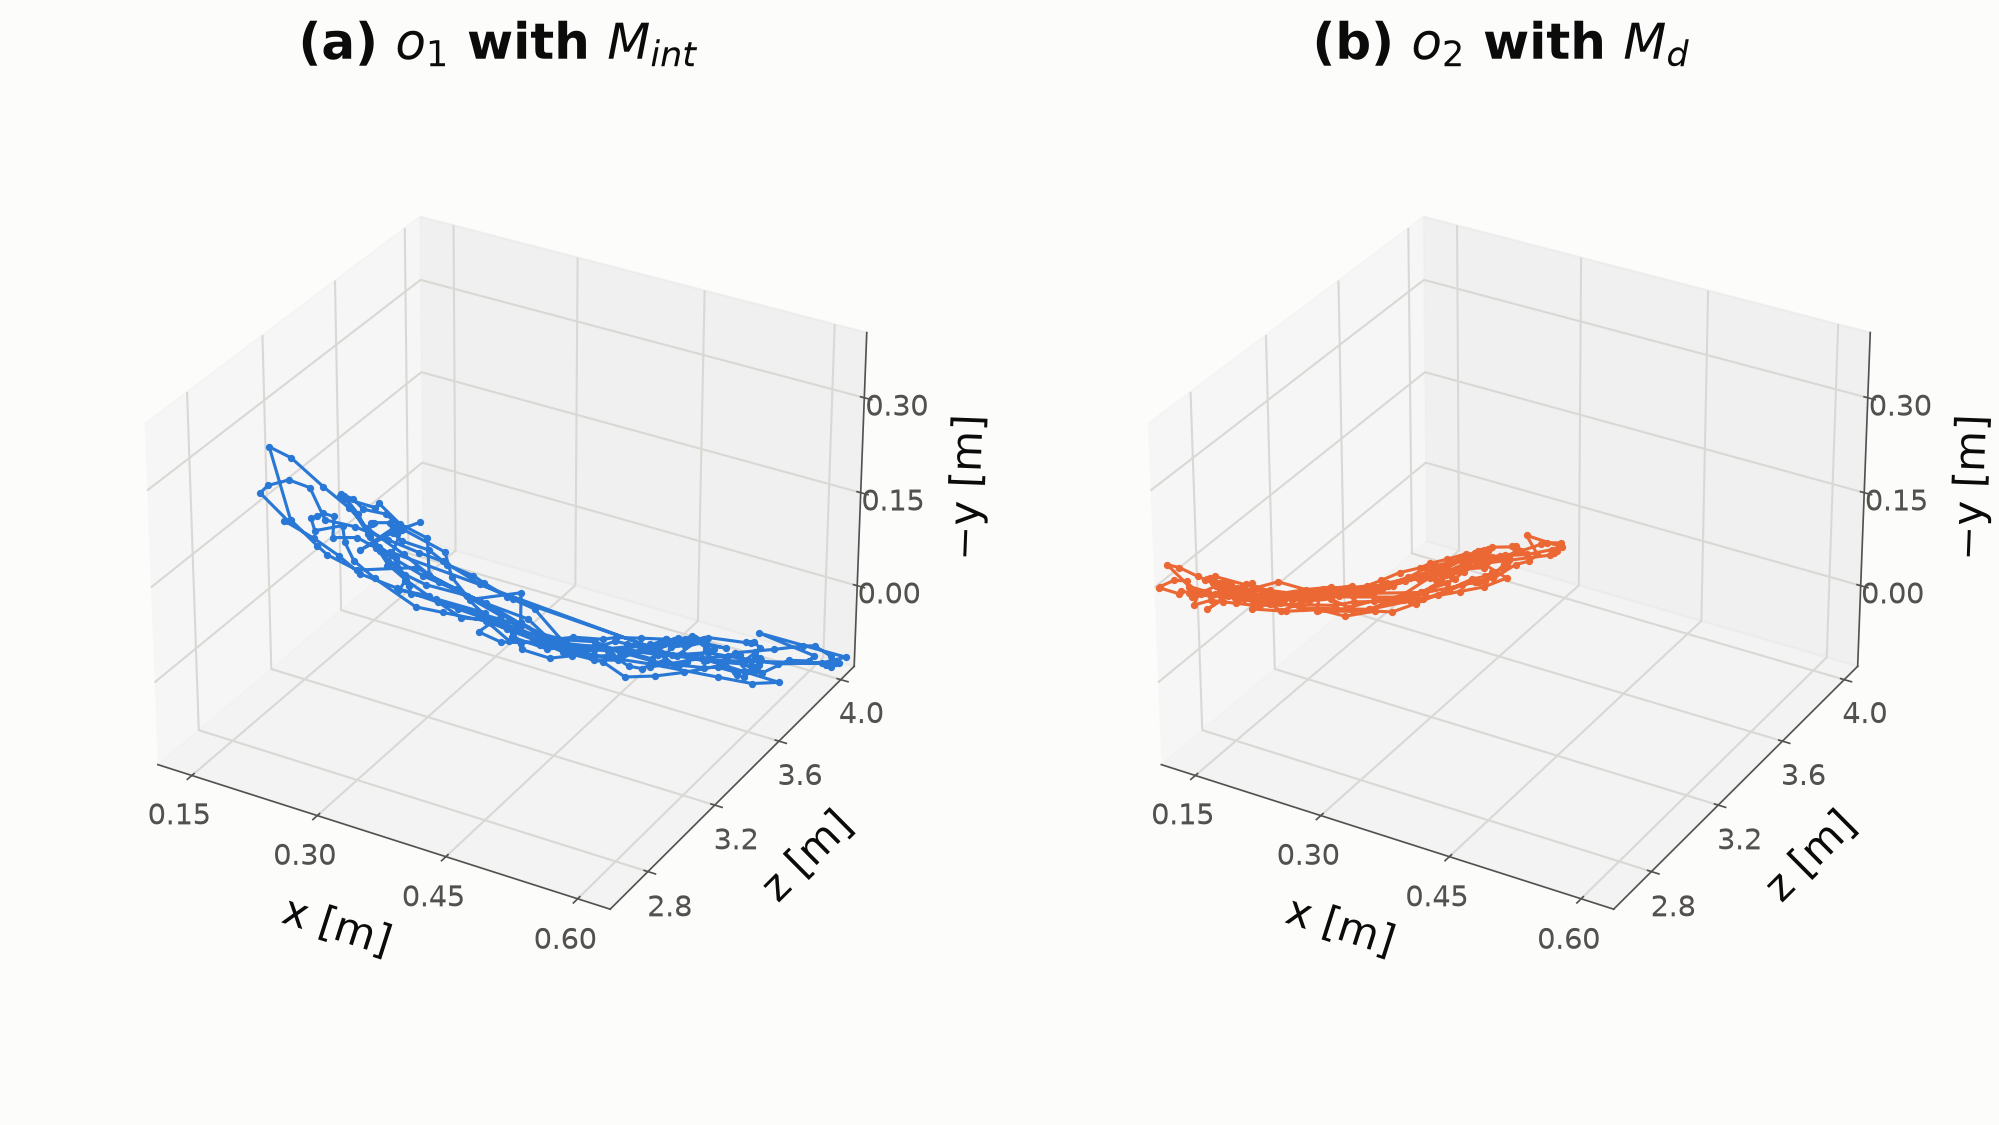

**Q1 (d) - training and validation loss of f_theta**

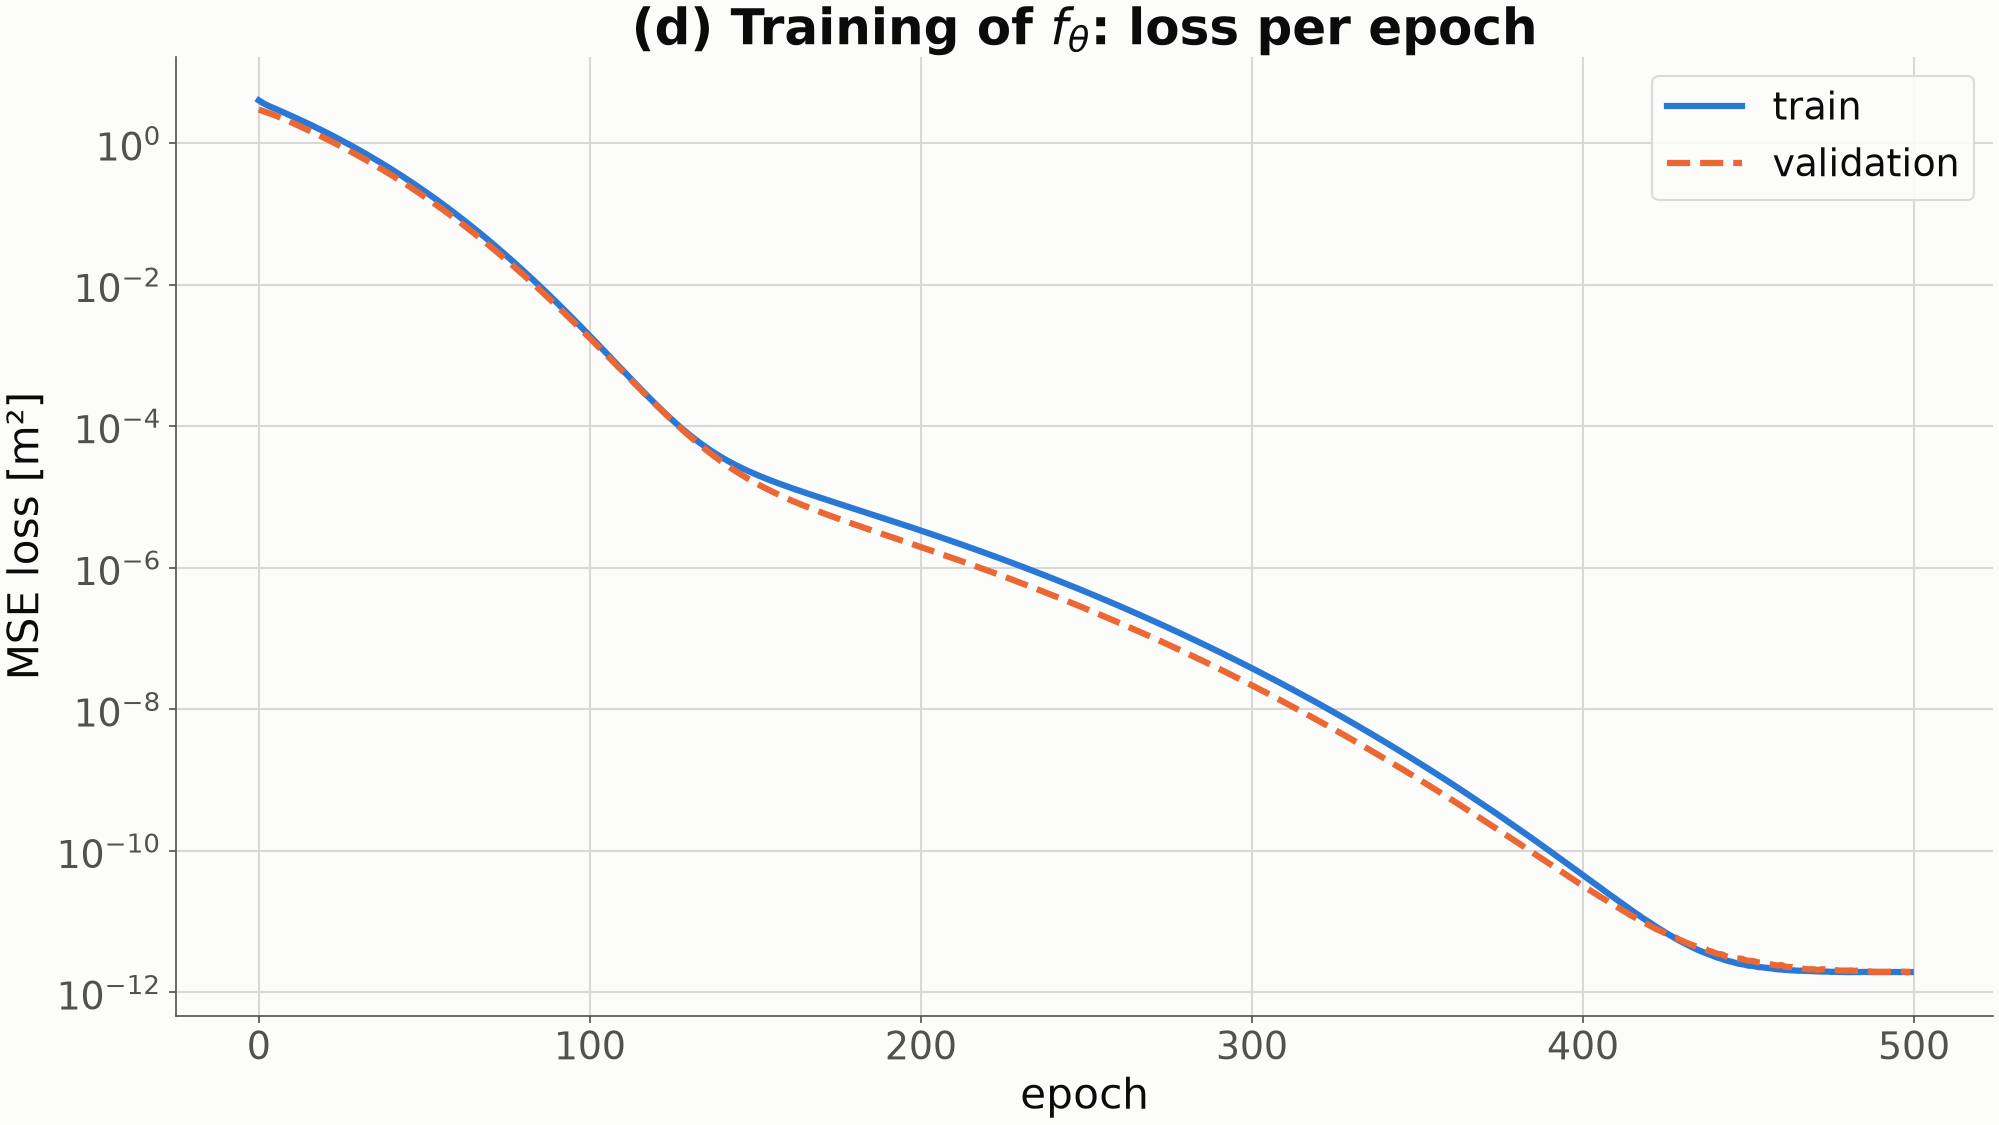

**Q1 (d) - predicted o2* against true o2 on the test set, with RMSE, MAE and R²**

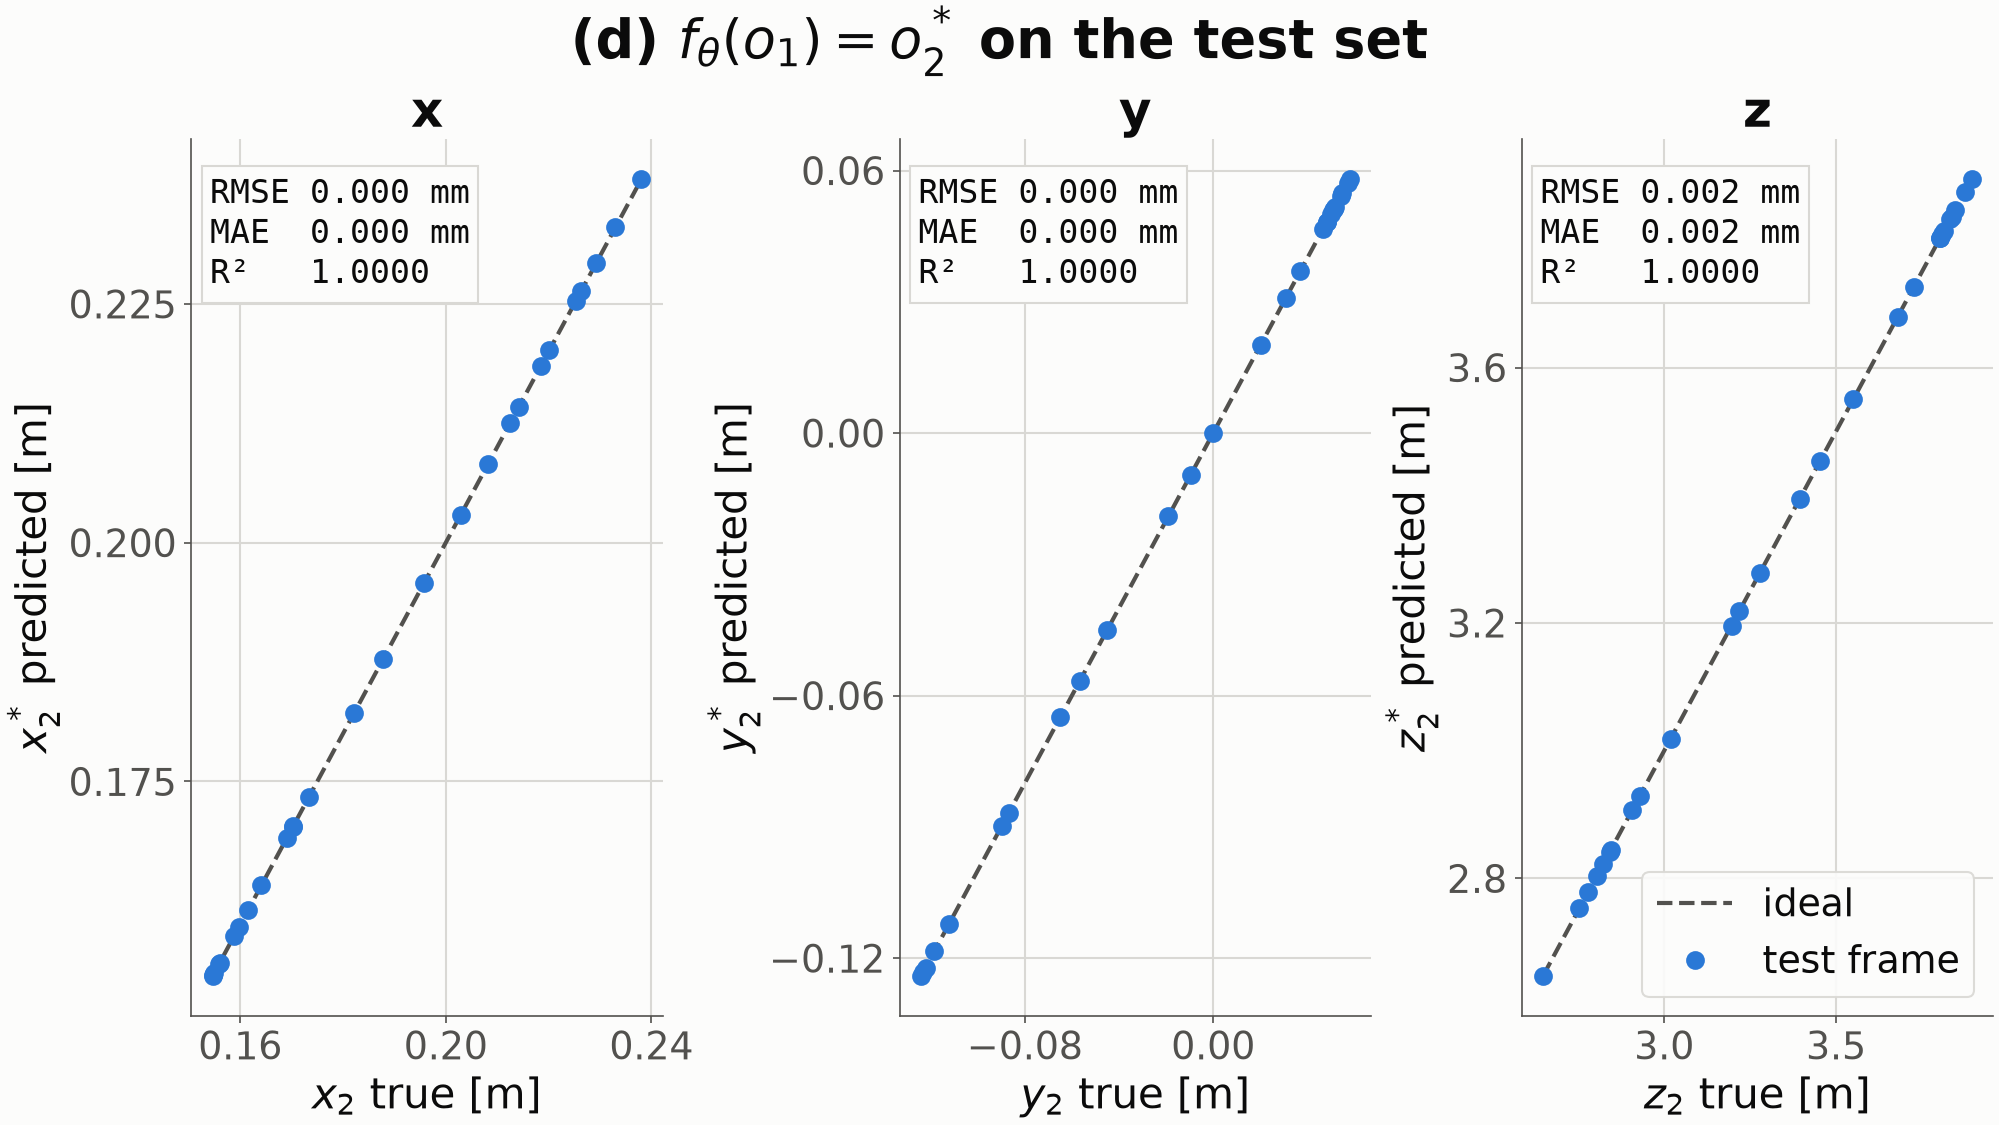

**Q1 (e) - Euclidean error (i) |o1 - o2| and (ii) |o1 - o2*|**

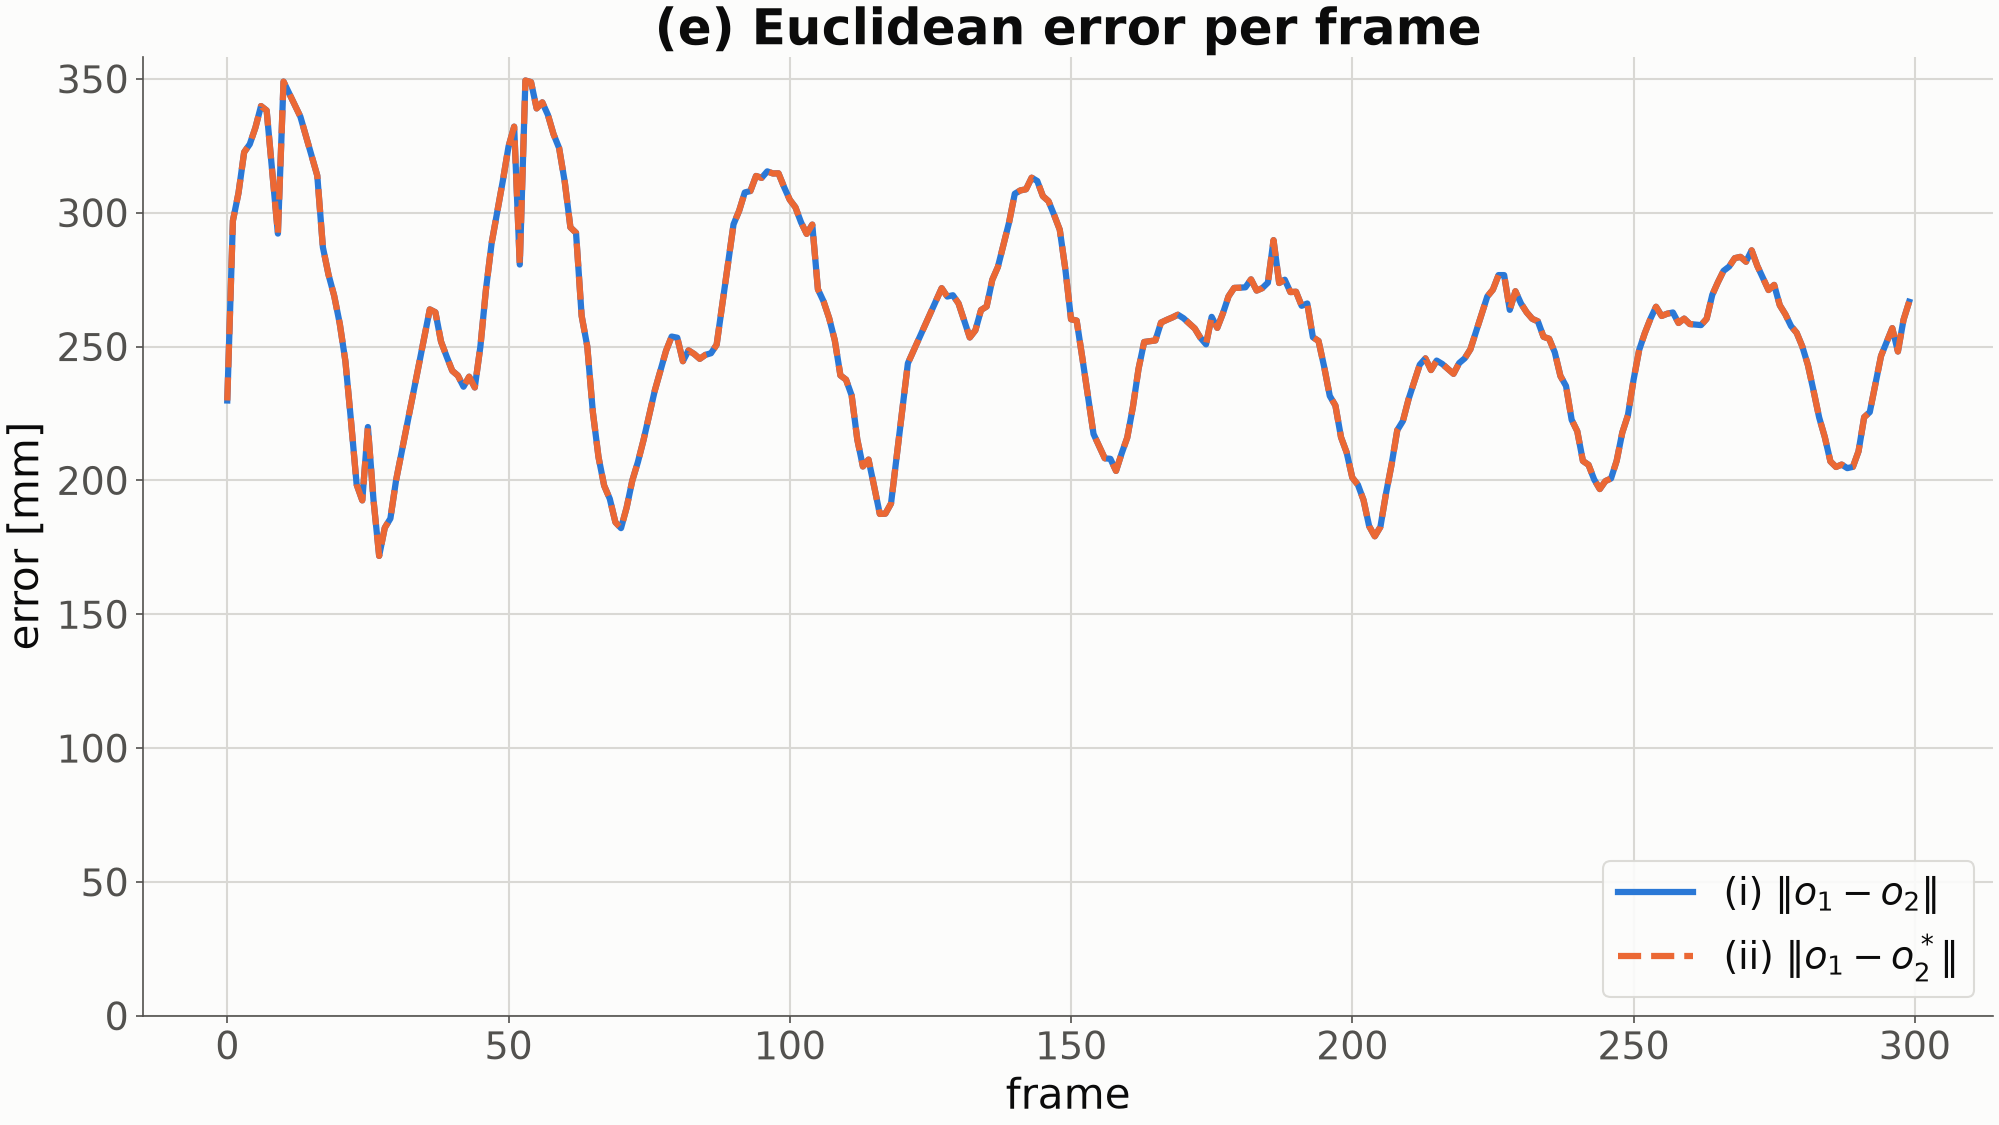

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path

from IPython.display import Image, Markdown, display

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------
RUN_Q1 = True   # False -> keep q1/result/ and only show the figures (YOLO + training take a while)

def find_root(name):
    """{name}/, whichever directory the notebook was opened from."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (parent / name, parent / "Assignment2" / name):
            if (candidate / "main.py").is_file():
                return candidate
    raise FileNotFoundError(f"{name}/ not found - open this notebook inside the repository")


def run_main(root):
    """Run main.py inside root/ and stream its output into the cell (Agg: the figures go to result/, no windows)."""
    print(f"$ python main.py   (in {root})", flush=True)
    t0 = time.time()
    proc = subprocess.Popen([sys.executable, "main.py"], cwd=root, text=True, bufsize=1,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            env={**os.environ, "MPLBACKEND": "Agg"})
    for line in proc.stdout:
        print("  " + line.rstrip(), flush=True)
    proc.wait()
    print(f"  [exit {proc.returncode}, {time.time() - t0:.0f} s]", flush=True)
    return proc.returncode


# ------------------------------------------------------------
# 2. PIPELINE
# main.py: YOLO from Assignment 1 finds the load, the L515 depth gives d,
# M_int and M_d back-project it to o1 and o2, the one-layer perceptron learns o2*.
# ------------------------------------------------------------
Q1 = find_root("q1")
if RUN_Q1:
    run_main(Q1)
else:
    print("pipeline skipped - reusing the figures already in q1/result/")

# ------------------------------------------------------------
# 3. RESULTS
# ------------------------------------------------------------
for name, caption in [
    ("q1_trajectories.png", "Q1 (a) (b) - centre of the load with M_int (o1) and with M_d (o2)"),
    ("q1_training.png", "Q1 (d) - training and validation loss of f_theta"),
    ("q1_kpis.png", "Q1 (d) - predicted o2* against true o2 on the test set, with RMSE, MAE and R²"),
    ("q1_error.png", "Q1 (e) - Euclidean error (i) |o1 - o2| and (ii) |o1 - o2*|"),
]:
    path = Q1 / "result" / name
    if path.exists():
        display(Markdown(f"**{caption}**"))
        display(Image(filename=str(path)))

# Q2. Lidar &nbsp;&nbsp;&nbsp; 10 + 15 = 25 points

**(a)** Use Ouster lidar in Lab to record the trajectory of swinging load. Find the center of
swinging load for all frames, and plot them.

**(b)** Leverage KISS ICP to find the pose of center of load in consecutive lidar frame. You can
use the off the shelf KISS-ICP algorithm, however, it is expected that student understand KISS
ICP, its working principle, uses and drawbacks, and present during the presentations. Further
present the pose of object obtained from KISS-ICP from the data in dataset above.

---

$ python main.py   (in /home/havard/hand_in/MAS512_Assignment_2/q2)


  /home/havard/hand_in/MAS512_Assignment_2/q2/main.py:95: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


    plt.show()


  99 lidar frames


  (a) centre of the load, min: [0.643 1.35  0.135] max: [0.782 2.139 0.231] [m]


...

   [ 0.099  0.965  0.244  1.534]


   [ 0.043 -0.249  0.968  0.235]


   [ 0.     0.     0.     1.   ]]


  [exit 0, 7 s]


**Q2 (a) - centre of the swinging load in all frames**

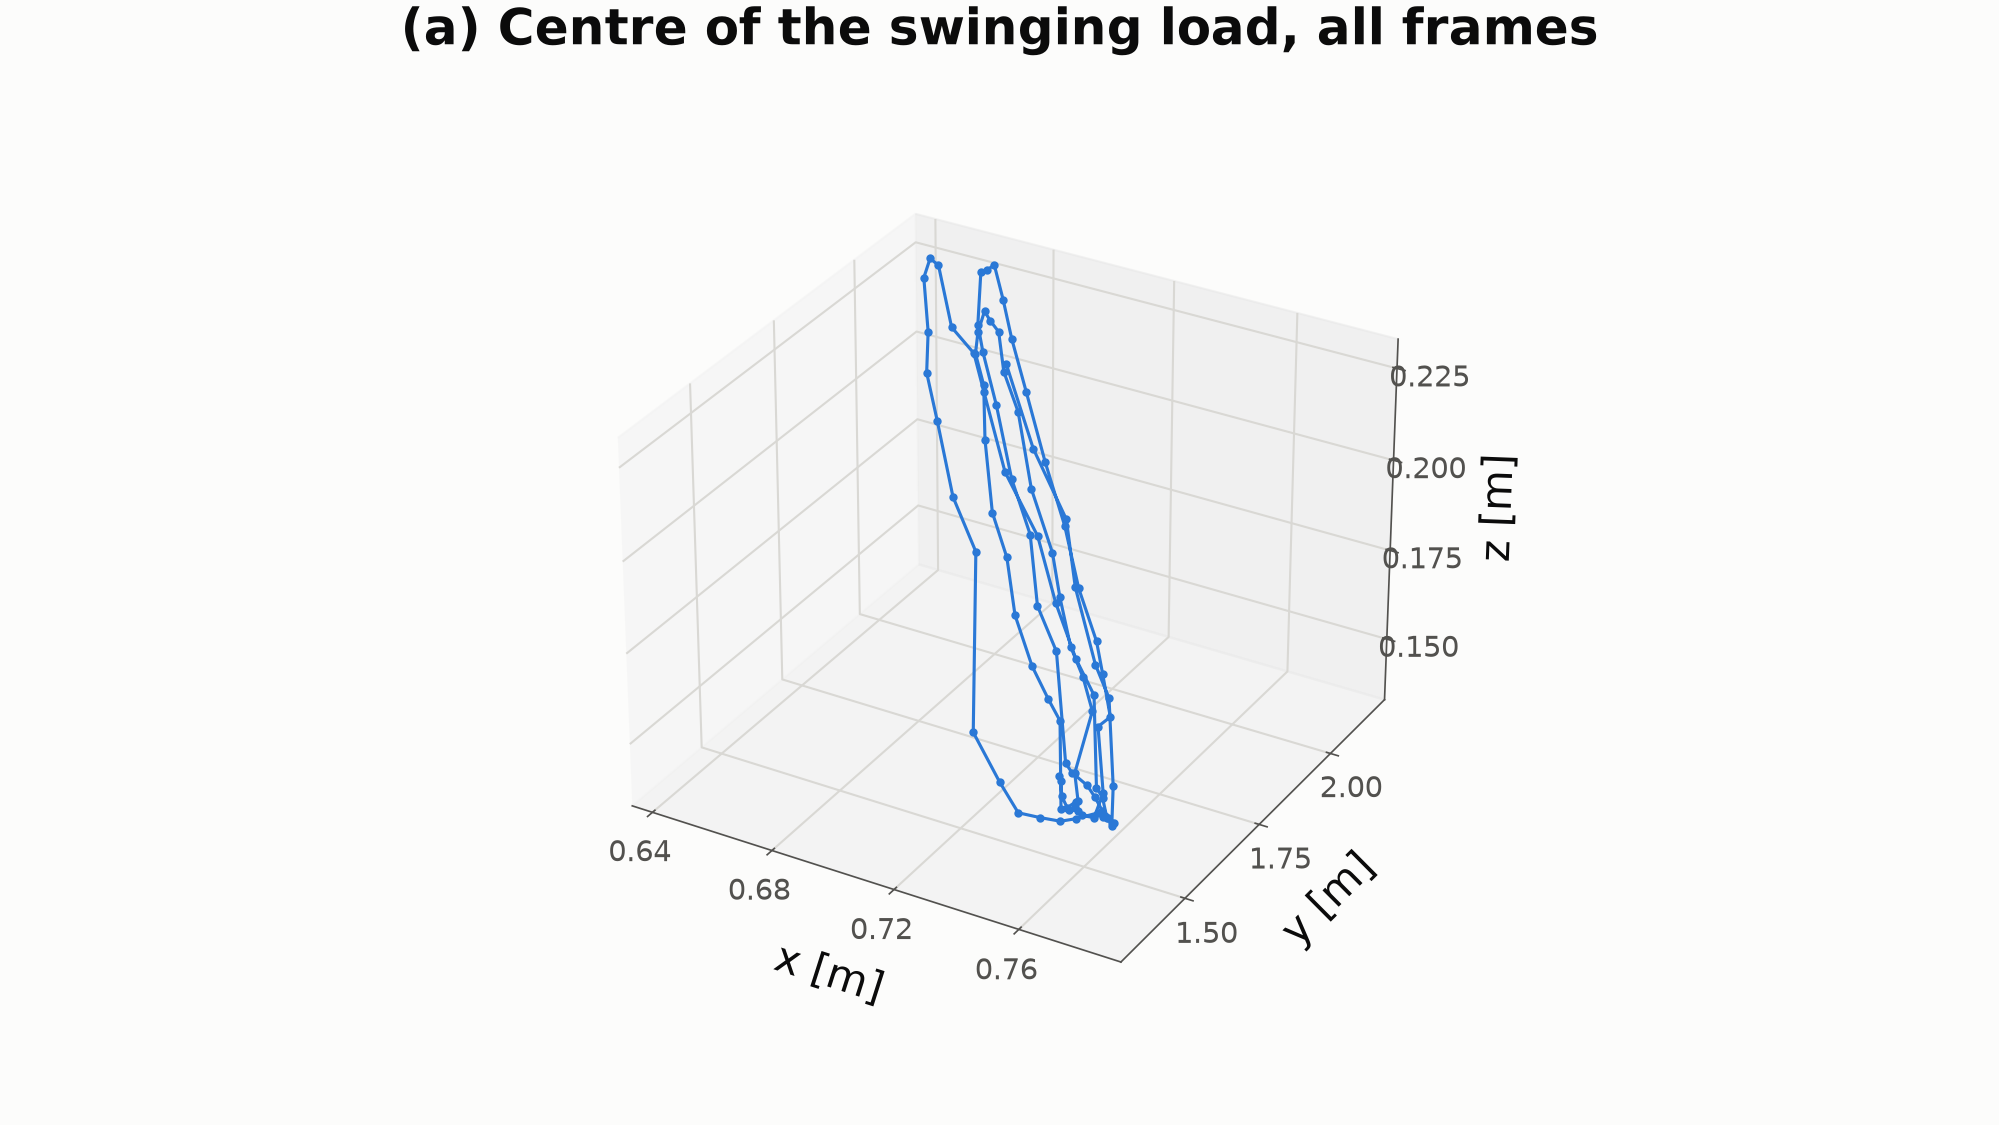

**Q2 (a) - the same trajectory seen from the three axes**

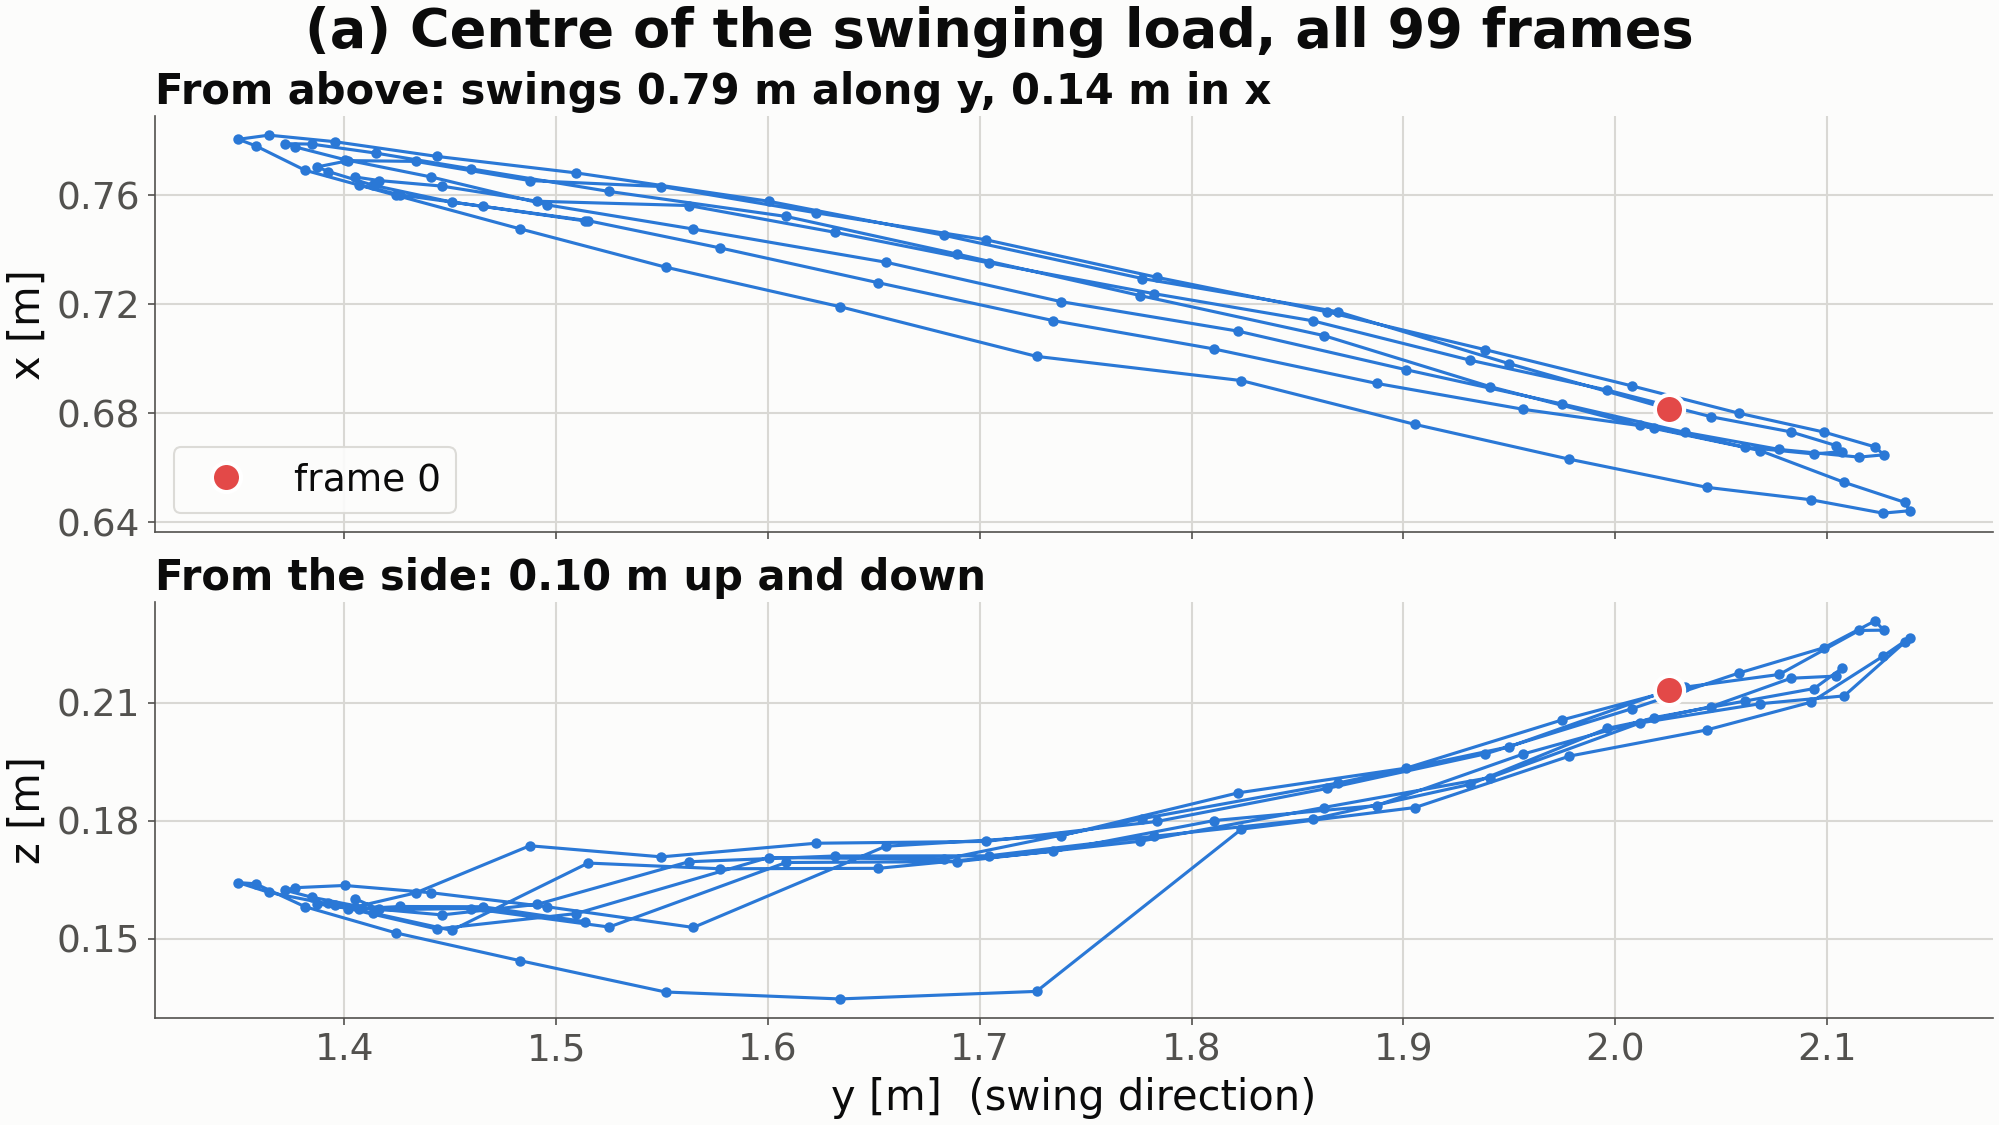

**Q2 (b) - position of the load centre from KISS-ICP against the cluster centroid**

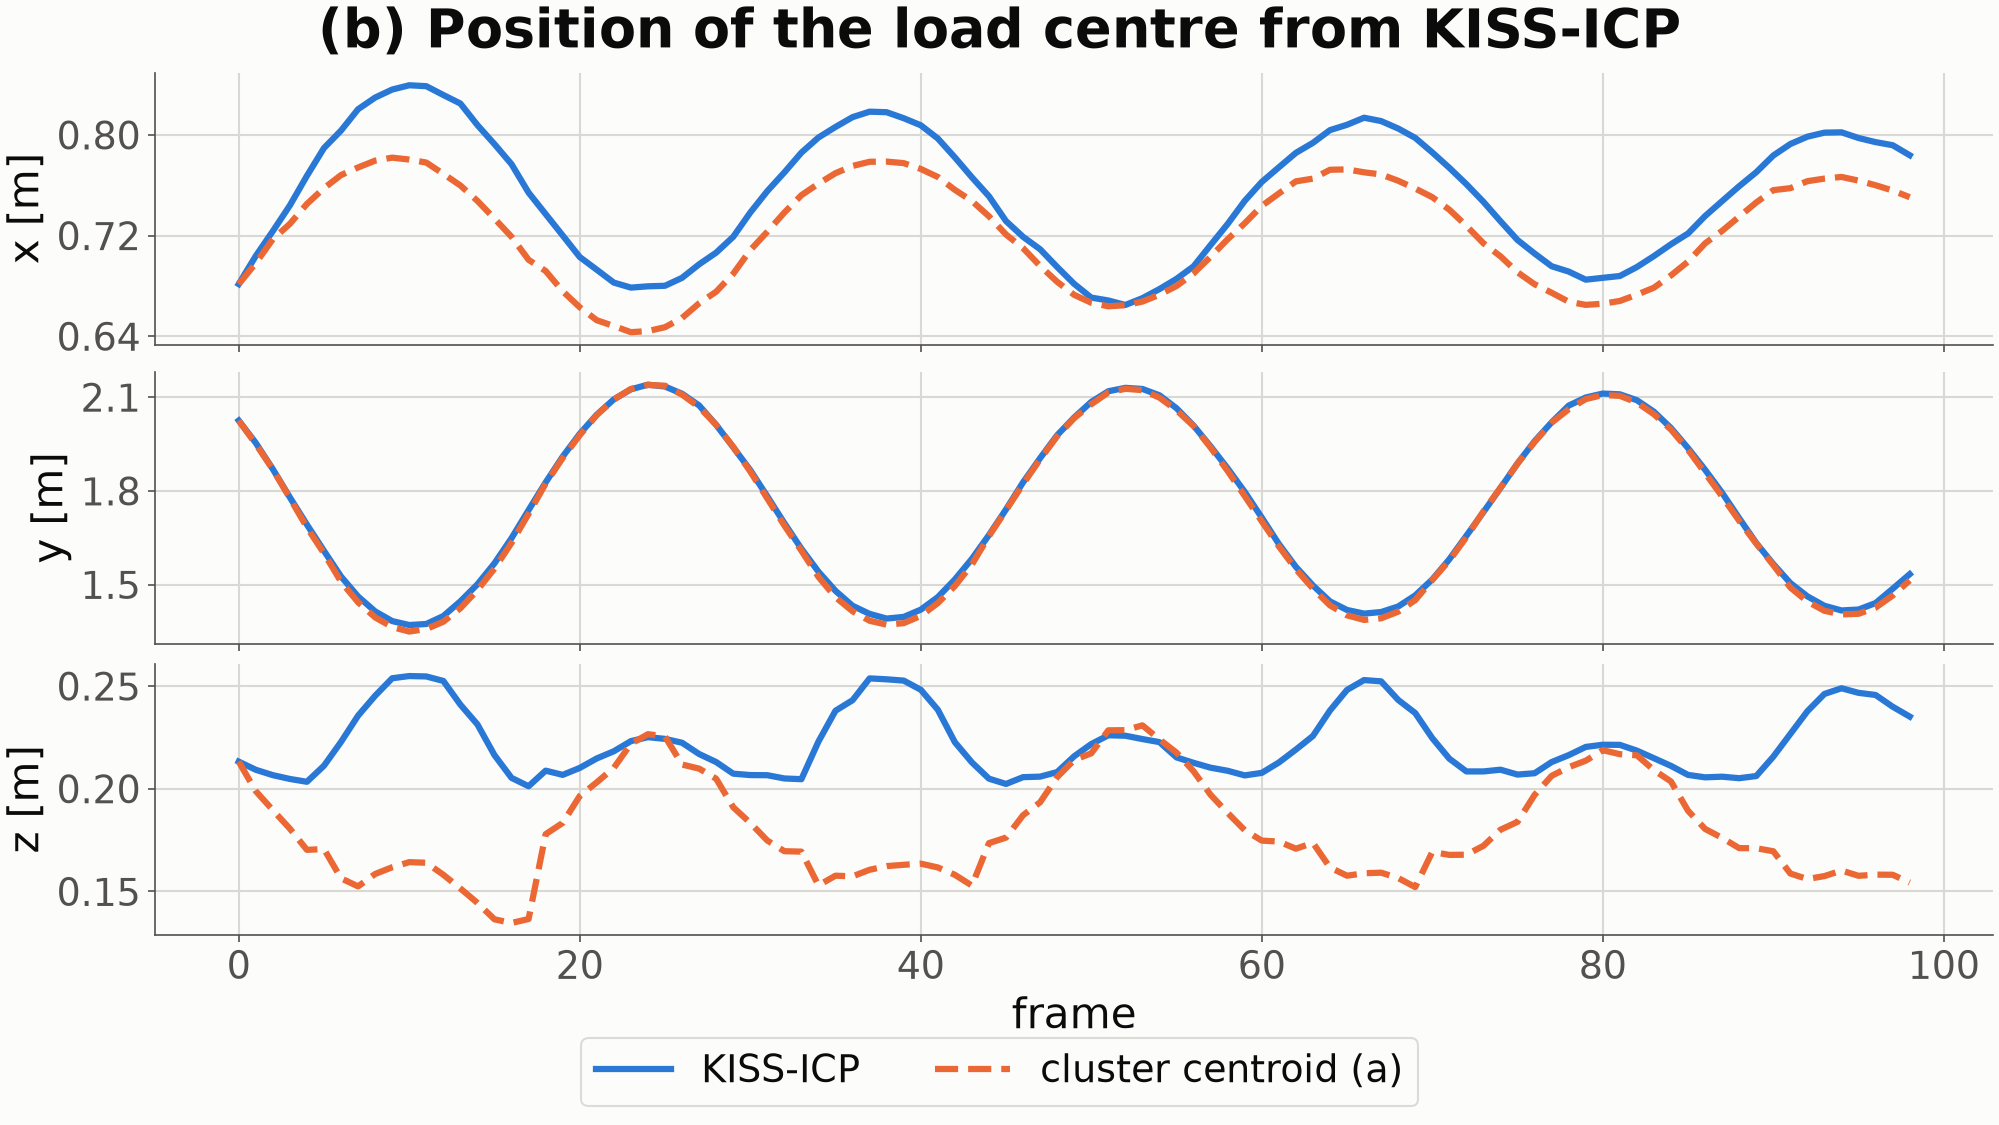

**Q2 (b) - orientation of the load from KISS-ICP**

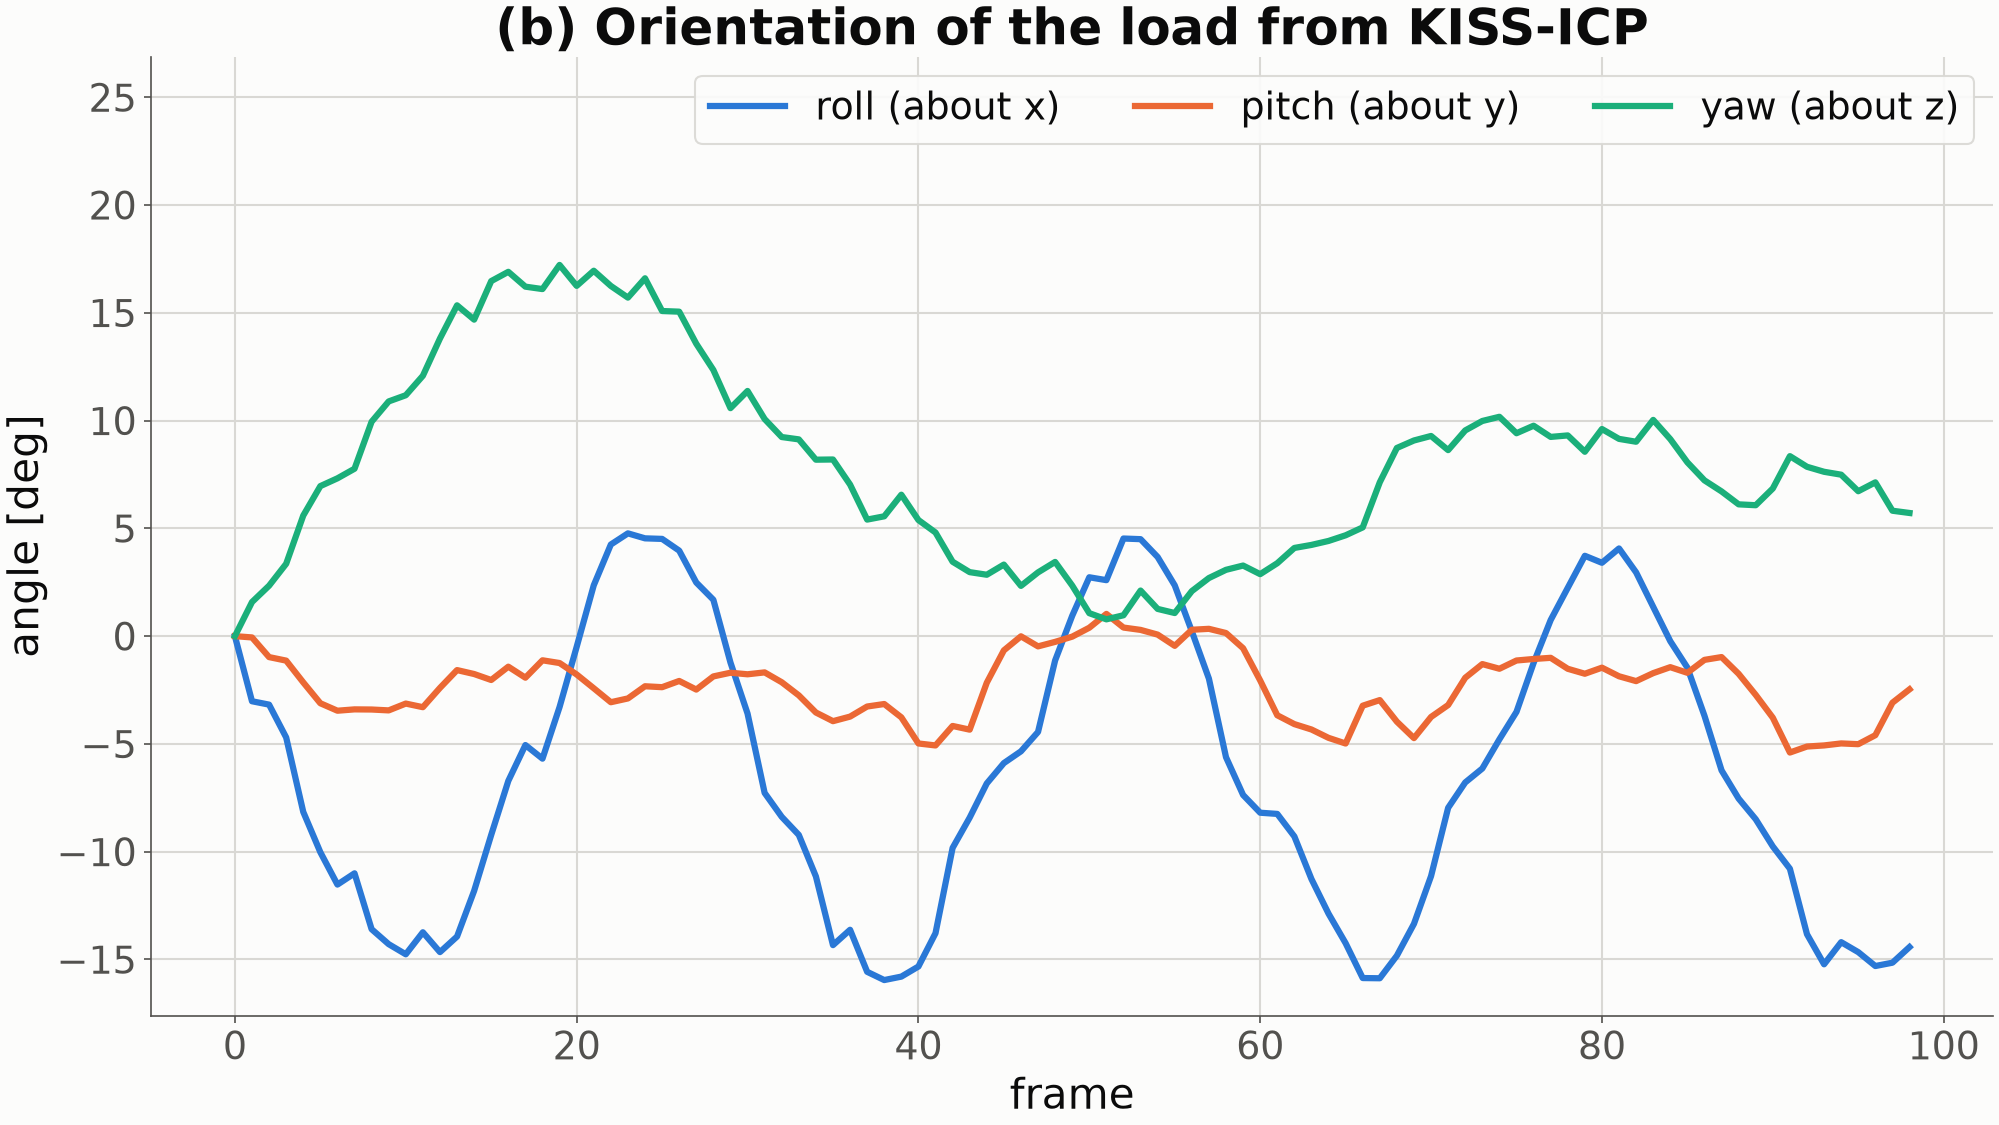

In [2]:
import os
import subprocess
import sys
import time
from pathlib import Path

from IPython.display import Image, Markdown, display

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------
RUN_Q2 = True   # False -> keep q2/result/ and only show the figures

def find_root(name):
    """{name}/, whichever directory the notebook was opened from."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (parent / name, parent / "Assignment2" / name):
            if (candidate / "main.py").is_file():
                return candidate
    raise FileNotFoundError(f"{name}/ not found - open this notebook inside the repository")


def run_main(root):
    """Run main.py inside root/ and stream its output into the cell (Agg: the figures go to result/, no windows)."""
    print(f"$ python main.py   (in {root})", flush=True)
    t0 = time.time()
    proc = subprocess.Popen([sys.executable, "main.py"], cwd=root, text=True, bufsize=1,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            env={**os.environ, "MPLBACKEND": "Agg"})
    for line in proc.stdout:
        print("  " + line.rstrip(), flush=True)
    proc.wait()
    print(f"  [exit {proc.returncode}, {time.time() - t0:.0f} s]", flush=True)
    return proc.returncode


# ------------------------------------------------------------
# 2. PIPELINE
# main.py: read the Ouster .pcap, crop + DBSCAN to find the load and its centroid (a),
# then register the load's points frame after frame with KISS-ICP for its pose (b).
# ------------------------------------------------------------
Q2 = find_root("q2")
if RUN_Q2:
    run_main(Q2)
else:
    print("pipeline skipped - reusing the figures already in q2/result/")

# ------------------------------------------------------------
# 3. RESULTS
# ------------------------------------------------------------
for name, caption in [
    ("q2_centres.png", "Q2 (a) - centre of the swinging load in all frames"),
    ("q2_centres_views.png", "Q2 (a) - the same trajectory seen from the three axes"),
    ("q2_pose_position.png", "Q2 (b) - position of the load centre from KISS-ICP against the cluster centroid"),
    ("q2_pose_orientation.png", "Q2 (b) - orientation of the load from KISS-ICP"),
]:
    path = Q2 / "result" / name
    if path.exists():
        display(Markdown(f"**{caption}**"))
        display(Image(filename=str(path)))

# Q3. Camera-Lidar fusion &nbsp;&nbsp;&nbsp; 10 + 15 = 25 points

KITTI data set is comprehensive data set used for benchmarking different algorithms. As this
assignment has large data set e.g. KITTI data set, students use UiA's high performance computing
server - coder.internal.uia.no/.

**(a)** Get familiar with the KITTI data set. There are multiple cameras, and Lidar used. It
contains the rich information about - images taken from cameras, point cloud taken from lidar,
camera matrices. Illustrate your understanding in presentation.

**(b)** Download data from here. Use the training data set. Perform the lidar-camera fusion.
Choose random five images from the training/

- **(i)** project them on the lidar frame or vice versa.
- **(ii)** Detect the object in the scene, place bounding box around it, measure the distance of
  object (shown by color bar) and display near the bounding box
- **(iii)** Validate your estimation of distance with ground truth

The KITTI training set is too large to keep locally, so Q3 was run on coder. The file structure
on the server is:

```
├── output/                 the figures written by the code
├── codes/                  the same as q3/ here
│   ├── task1.py            (b)(i)   projection
│   ├── task2.py            (b)(ii)  detection and distance
│   └── task3.py            (b)(iii) validation against the ground truth
└── data/                   the KITTI dataset
    ├── devkit_object/
    ├── gt_database/
    ├── testing/
    └── training/           the split the scripts read
        ├── calib/          camera matrices P2, R0_rect, Tr_velo_to_cam
        ├── image_2/        left colour camera images
        ├── label_2/        ground truth: class, 2D box, 3D position
        ├── velodyne/       lidar point clouds (x, y, z, reflectance)
        └── velodyne_reduced/
```

The cell below shows the code and the figures brought back from the server.

---

In [3]:
from pathlib import Path

from IPython.display import Image, Markdown, display

# ------------------------------------------------------------
# 1. THE CODE (run on coder: python task1.py, task2.py, task3.py inside q3/)
# ------------------------------------------------------------
def find_root(name):
    """{name}/, whichever directory the notebook was opened from."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (parent / name, parent / "Assignment2" / name):
            if (candidate / "task1.py").is_file():
                return candidate
    raise FileNotFoundError(f"{name}/ not found - open this notebook inside the repository")


Q3 = find_root("q3")
for script, caption in [
    ("task1.py", "Q3 (b)(i) - lidar points projected onto the camera image"),
    ("task2.py", "Q3 (b)(ii) - YOLO boxes with the lidar distance of each object"),
    ("task3.py", "Q3 (b)(iii) - estimated distance against the KITTI ground truth"),
]:
    display(Markdown(f"**{caption}** - `q3/{script}`"))
    # a markdown code block follows the editor theme (IPython's Code() is always white)
    display(Markdown(f"```python\n{(Q3 / script).read_text()}\n```"))

# ------------------------------------------------------------
# 2. RESULTS (the figures task1-3 wrote to q3/output/ on the server)
# ------------------------------------------------------------
OUT = Q3 / "output"
for pattern, caption in [
    ("*_projection.png", "Q3 (b)(i) - projection"),
    ("*_detection.png", "Q3 (b)(ii) - detection and distance"),
    ("validation.png", "Q3 (b)(iii) - estimated vs ground truth distance"),
]:
    for path in sorted(OUT.glob(pattern)):
        display(Markdown(f"**{caption}, {path.stem}**"))
        display(Image(filename=str(path)))
if not any(OUT.glob("*.png")):
    print("no figures in q3/output/")

**Q3 (b)(i) - lidar points projected onto the camera image** - `q3/task1.py`

```python
# Q3 (b)(i) : Lidar-camera fusion on KITTI
# projecting the lidar points onto the camera image for 5 random frames

#comand to install reqired packages
#pip install numpy opencv-python-headless matplotlib

import os
import random
import cv2
import numpy as np
import matplotlib
matplotlib.use("Agg")  # no screen on the server so we save the plots as images
import matplotlib.pyplot as plt


# folders
script_folder = os.path.dirname(os.path.abspath(__file__))
data_folder = os.path.join(script_folder, "..", "data", "training")
output_folder = os.path.join(script_folder, "..", "output")




# function to read the calibration fil
def read_calib(filename):
    calib = {}
    f = open(filename)
    for line in f:
        # split the line into name and numbers, convert the numbers to a numpy array"
        if ":" in line:
            name, numbers = line.split(":", 1)
            values = []
            for n in numbers.split():
                values.append(float(n))
            calib[name.strip()] = np.array(values)
    f.close()

    # P2 is the projection matrix for the color camera 
    P2 = calib["P2"].reshape(3, 4)
    # R0_rect is 3x3, we put it in a 4x4 identity matrix
    R0 = np.eye(4)
    R0[0:3, 0:3] = calib["R0_rect"].reshape(3, 3)
    # Tr_velo_to_cam is 3x4, also put it in a 4x4 identity matrix
    Tr = np.eye(4)
    Tr[0:3, 0:4] = calib["Tr_velo_to_cam"].reshape(3, 4)

    return P2, R0, Tr


# get all the frame names from the image folder
frame_list = []
for file in sorted(os.listdir(os.path.join(data_folder, "image_2"))):
    if file.endswith(".png"):
        frame_list.append(file.replace(".png", ""))

# pick 5 random frames
chosen_frames = random.sample(frame_list, 5)
print("frames chosen:", chosen_frames)


for frame in chosen_frames:

    # load the image, opencv uses BGR so we change it to RGB
    image = cv2.imread(os.path.join(data_folder, "image_2", frame + ".png"))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height = image.shape[0]
    width = image.shape[1]

    # load the lidar points, 4 numbers per point (x, y, z, reflectance)
    lidar = np.fromfile(os.path.join(data_folder, "velodyne", frame + ".bin"), dtype=np.float32)
    lidar = lidar.reshape(-1, 4)

    # load the calibration for this frame
    P2, R0, Tr = read_calib(os.path.join(data_folder, "calib", frame + ".txt"))

    # take x, y, z and add a column of ones -> [x, y, z, 1]
    xyz = lidar[:, 0:3]
    ones = np.ones((xyz.shape[0], 1))
    points = np.hstack((xyz, ones))

    # lidar frame -> camera frame
    points_cam = R0 @ Tr @ points.T

    # remove points behind the camera (z < 0)
    # if we dont do this they get flipped and show up in the image
    points_cam = points_cam[:, points_cam[2] > 0]

    # camera frame to image plane
    pixels = P2 @ points_cam
    u = pixels[0] / pixels[2]
    v = pixels[1] / pixels[2]

    # depth is the z value in the camera frame 
    depth = points_cam[2]

    # only keep the points that are inside the image since lidar is 360 degrees
    # and the camera is only 90 degrees
    inside = (u >= 0) & (u < width) & (v >= 0) & (v < height)
    u = u[inside]
    v = v[inside]
    depth = depth[inside]

    print("frame", frame, ":", len(lidar), "lidar points,", len(u), "inside the image")

    # plot the image with the lidar points on top
    # jet_r makes close points red and far points blue
    plt.figure(figsize=(16, 5))
    plt.imshow(image)
    plt.scatter(u, v, c=depth, cmap="jet_r", s=1)
    plt.colorbar(label="Depth [m]", fraction=0.015, pad=0.01)  # thin colour bar close to the image
    plt.title("Lidar projected onto image - frame " + frame)
    plt.axis("off")
    plt.savefig(os.path.join(output_folder, frame + "_projection.png"))
    plt.close()


```

**Q3 (b)(ii) - YOLO boxes with the lidar distance of each object** - `q3/task2.py`

```python
#Task B(ii): detect people and cars, draw a bounding box and show the lidar distance

from pathlib import Path
import random
import cv2
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from ultralytics import YOLO

DATA = Path(__file__).resolve().parent.parent / "data" / "training"
OUT = Path(__file__).resolve().parent.parent / "output"

model = YOLO("yolo11n.pt")  # pretrained on COCO
random.seed(0)

# get 5 random frames
frames = random.sample([p.stem for p in (DATA / "image_2").glob("*.png")], 5)

for frame in frames:
    img = cv2.imread(str(DATA / "image_2" / f"{frame}.png"))
    lidar = np.fromfile(DATA / "velodyne" / f"{frame}.bin", dtype=np.float32).reshape(-1, 4)

    # read calibration same as in task 1
    calib = {}
    for line in open(DATA / "calib" / f"{frame}.txt"):
        if ":" in line:
            name, numbers = line.split(":", 1)
            calib[name] = np.array(numbers.split(), dtype=float)
    P2 = calib["P2"].reshape(3, 4)
    R0 = np.eye(4); R0[:3, :3] = calib["R0_rect"].reshape(3, 3)
    Tr = np.eye(4); Tr[:3, :4] = calib["Tr_velo_to_cam"].reshape(3, 4)

    # lidar to image (sensor fusion)
    pts = np.hstack((lidar[:, :3], np.ones((len(lidar), 1))))
    cam = R0 @ Tr @ pts.T
    cam = cam[:, cam[2] > 0] # only points in front of the camera
    pix = P2 @ cam
    u, v, depth = pix[0] / pix[2], pix[1] / pix[2], cam[2]
    h, w = img.shape[:2]
    keep = (u >= 0) & (u < w) & (v >= 0) & (v < h)
    u, v, depth = u[keep], v[keep], depth[keep]

    # detect people class 0 and cars class 2 and higher probability than 0.5
    result = model(img, conf=0.5, classes=[0, 2], verbose=False)[0]

#   plot the results: image, bounding boxes, lidar points inside the boxes and distance to the object
    plt.figure(figsize=(16, 5))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    cmap = plt.cm.jet_r
    norm = plt.Normalize(0, 80)              # color scale 0-80 m
    in_any_box = np.zeros(len(u), dtype=bool)  # lidar points that are inside a box

    print("frame", frame)
    #had help from ai to write the following code
    for (x1, y1, x2, y2), cls, conf in zip(result.boxes.xyxy.tolist(), result.boxes.cls.tolist(), result.boxes.conf.tolist()):
        in_box = (u >= x1) & (u <= x2) & (v >= y1) & (v <= y2)
        in_any_box |= in_box

        # centre of the box, distance from the lidar points in the middle half of the box
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        bw, bh = x2 - x1, y2 - y1
        near_centre = (abs(u - cx) <= bw / 4) & (abs(v - cy) <= bh / 4)
        if not near_centre.any():
            continue
        dist = np.median(depth[near_centre])   # distance to the object
        color = cmap(norm(dist))               # box color = distance

        label = f"{model.names[int(cls)]} {conf:.2f} | {dist:.1f} m"
        print("  ", label, f"centre=({cx:.0f}, {cy:.0f})")

        plt.gca().add_patch(plt.Rectangle((x1, y1), bw, bh, fill=False, edgecolor=color, linewidth=2))
        plt.plot(cx, cy, "o", color=color, markeredgecolor="black")   # centre point
        plt.text(x1, y1 - 3, label, fontsize=8, backgroundcolor=color)

    # only draw the lidar points inside the boxes (x dir, y dir, c=color value, cmap=colormap, norm=normalization, s=size of the points)
    plt.scatter(u[in_any_box], v[in_any_box], c=depth[in_any_box], cmap=cmap, norm=norm, s=2)

    plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=plt.gca(), label="Depth [m]")
    plt.axis("off")
    plt.savefig(OUT / f"{frame}_detection.png", bbox_inches="tight")
    plt.close()
```

**Q3 (b)(iii) - estimated distance against the KITTI ground truth** - `q3/task3.py`

```python
#Task B(iii): validate the estimated distance against the ground truth in label_2

from pathlib import Path
import random
import cv2
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from ultralytics import YOLO
random.seed(0)

DATA = Path(__file__).resolve().parent.parent / "data" / "training"
OUT = Path(__file__).resolve().parent.parent / "output"
 # pretrained on COCO
model = YOLO("yolo11n.pt") 
# which KITTI classes match the YOLO classes
GT_CLASS = {"car": ["Car"], "person": ["Pedestrian", "Person_sitting"]}

def iou(a, b):
    # overlap between two boxes (x1, y1, x2, y2), 0 = no overlap, 1 = same box
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    return inter / (area_a + area_b - inter)

#random.seed(0)  # same 5 frames every time
frames = random.sample(sorted(p.stem for p in (DATA / "image_2").glob("*.png")), 5)

results = []  # (frame, class, estimated, ground truth)

for frame in frames:
    img = cv2.imread(str(DATA / "image_2" / f"{frame}.png"))
    lidar = np.fromfile(DATA / "velodyne" / f"{frame}.bin", dtype=np.float32).reshape(-1, 4)

    # read calibration
    calib = {}
    for line in open(DATA / "calib" / f"{frame}.txt"):
        if ":" in line:
            name, numbers = line.split(":", 1)
            calib[name] = np.array(numbers.split(), dtype=float)
    P2 = calib["P2"].reshape(3, 4)
    R0 = np.eye(4); R0[:3, :3] = calib["R0_rect"].reshape(3, 3)
    Tr = np.eye(4); Tr[:3, :4] = calib["Tr_velo_to_cam"].reshape(3, 4)

    # read ground truth: class, 2D box and distance z
    gt = []
    for line in open(DATA / "label_2" / f"{frame}.txt"):
        p = line.split()
        if p[0] != "DontCare":
            gt.append((p[0], [float(x) for x in p[4:8]], float(p[13])))

    # lidar -> image
    pts = np.hstack((lidar[:, :3], np.ones((len(lidar), 1))))
    cam = R0 @ Tr @ pts.T
    cam = cam[:, cam[2] > 0]
    pix = P2 @ cam
    u, v, depth = pix[0] / pix[2], pix[1] / pix[2], cam[2]
    h, w = img.shape[:2]
    keep = (u >= 0) & (u < w) & (v >= 0) & (v < h)
    u, v, depth = u[keep], v[keep], depth[keep]

    # detect people class 0 and cars class 2
    result = model(img, conf=0.5, classes=[0, 2], verbose=False)[0]

    print("frame", frame)
    for box, cls in zip(result.boxes.xyxy.tolist(), result.boxes.cls.tolist()):
        x1, y1, x2, y2 = box
        name = model.names[int(cls)]

        # estimated distance, same as Task2 (middle half of the box)
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        near_centre = (abs(u - cx) <= (x2 - x1) / 4) & (abs(v - cy) <= (y2 - y1) / 4)
        if not near_centre.any():
            continue
        est = np.median(depth[near_centre])

        # find the ground truth object of the same class with the most overlap
        same_class = [g for g in gt if g[0] in GT_CLASS[name]]
        if not same_class:
            print(f"   {name:6s} est={est:5.1f} m   no ground truth")
            continue
        best = max(same_class, key=lambda g: iou(box, g[1]))
        if iou(box, best[1]) < 0.5:
            print(f"   {name:6s} est={est:5.1f} m   no ground truth")
            continue

        true_z = best[2]
        results.append((frame, name, est, true_z))
        print(f"   {name:6s} est={est:5.1f} m   gt={true_z:5.1f} m   error={est - true_z:+5.1f} m")

# KPIs over all matched objects
est = np.array([r[2] for r in results])
true = np.array([r[3] for r in results])
err = est - true

print(f"\nmatched objects: {len(results)}")
print(f"MAE  (mean absolute error): {np.mean(abs(err)):.2f} m")
print(f"RMSE:                       {np.sqrt(np.mean(err ** 2)):.2f} m")
print(f"bias (mean error):          {np.mean(err):+.2f} m")
print(f"mean relative error:        {np.mean(abs(err) / true) * 100:.1f} %")

# estimated vs ground truth
plt.figure(figsize=(6, 6))
plt.scatter(true, est)
lim = max(true.max(), est.max()) + 5
plt.plot([0, lim], [0, lim], "k--", label="perfect (y = x)")
plt.xlabel("Ground truth distance [m]")
plt.ylabel("Estimated distance [m]")
plt.title("Estimated vs ground truth distance")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(OUT / "validation.png", bbox_inches="tight")
plt.close()
```

no figures in q3/output/


# Q4. Autonomous navigation and slip estimation &nbsp;&nbsp;&nbsp; 10 + 10 + 5 = 25 points

Webots - https://cyberbotics.com - is an open source light weight platform to simulate
robotics, perception, and control. This give us the platform to conceptualize and simulate
downstream tasks. Leveraging Webots perform the following tasks:

**(a) Baseline:** Instantiate a robot, and equip it with sensors - camera, lidar,
accelerometer, gyro, GPS, IMU etc on it. Then navigate in the world and move towards a
predefined object goal (e.g. cylinder sphere or .. with predefined colour) with collision
avoidance. At each time record the sensors data e.g. encoder data, lidar data, camera IMU
for example. Compute the longitudinal slip ($s_{long}$) as follows:

$$s_{long} = \frac{v_{enc} - v_x}{v_x}$$

where $v_{enc}$ is the velocity obtained from encoder $= \omega r$; $\omega$ and $r$ are the
angular velocity and radius of wheel. $v_x$ is the ground truth given from lidar, or the
webot simulation world. Feel free to choose.

**(b) Low slip conditions:** Simulate lower slip of your choice (varying the friction), then
repeat the same object goal navigation as above. Recalculate the longitudinal slip.

**(c)** Plot the slip for both cases along the trajectory that the robot navigates.

---

q4-webots : /home/havard/hand_in/MAS512_Assignment_2/q4-webots
webots    : NOT FOUND - install Webots R2025a, or set RUN_SIM = False
ffmpeg    : missing - animate_run.py falls back to a GIF

$ /home/havard/hand_in/MAS512_Assignment_2/.venv/bin/python -m pip install -q -r requirements.txt


  [exit 0, 2 s]



$ /home/havard/hand_in/MAS512_Assignment_2/.venv/bin/python tools/make_worlds.py


  written /home/havard/hand_in/MAS512_Assignment_2/q4-webots/worlds/city_baseline.wbt


  written /home/havard/hand_in/MAS512_Assignment_2/q4-webots/worlds/city_low_slip.wbt


...


$ /home/havard/hand_in/MAS512_Assignment_2/.venv/bin/python analysis/animate_run.py compare


  written figures/run_compare.gif (387 frames, 26 s)


  [exit 0, 102 s]


### Q4 (a) (b) - the same mission on two frictions

| run | μ wheel-floor | force dependent slip | outcome | time | path | median s_long | decoy colours ignored |
|---|---|---|---|---|---|---|---|
| (a) wet square | 0.25 | 0.03 | goal_reached | 47.5 s | 26.8 m | **+7.0 %** | 7 |
| (b) dry square | 1 | 0.0008 | goal_reached | 40.9 s | 25.8 m | **-0.1 %** | 7 |

The red beacon is not visible from the start and there are ten decoys: Toby has to search for it, recognise the colour and ignore the others. On the wet square the wheels turn faster than the robot advances, on the dry one the two velocities coincide.

**Q4 (c) - the toy city from above, trajectory coloured by s_long**

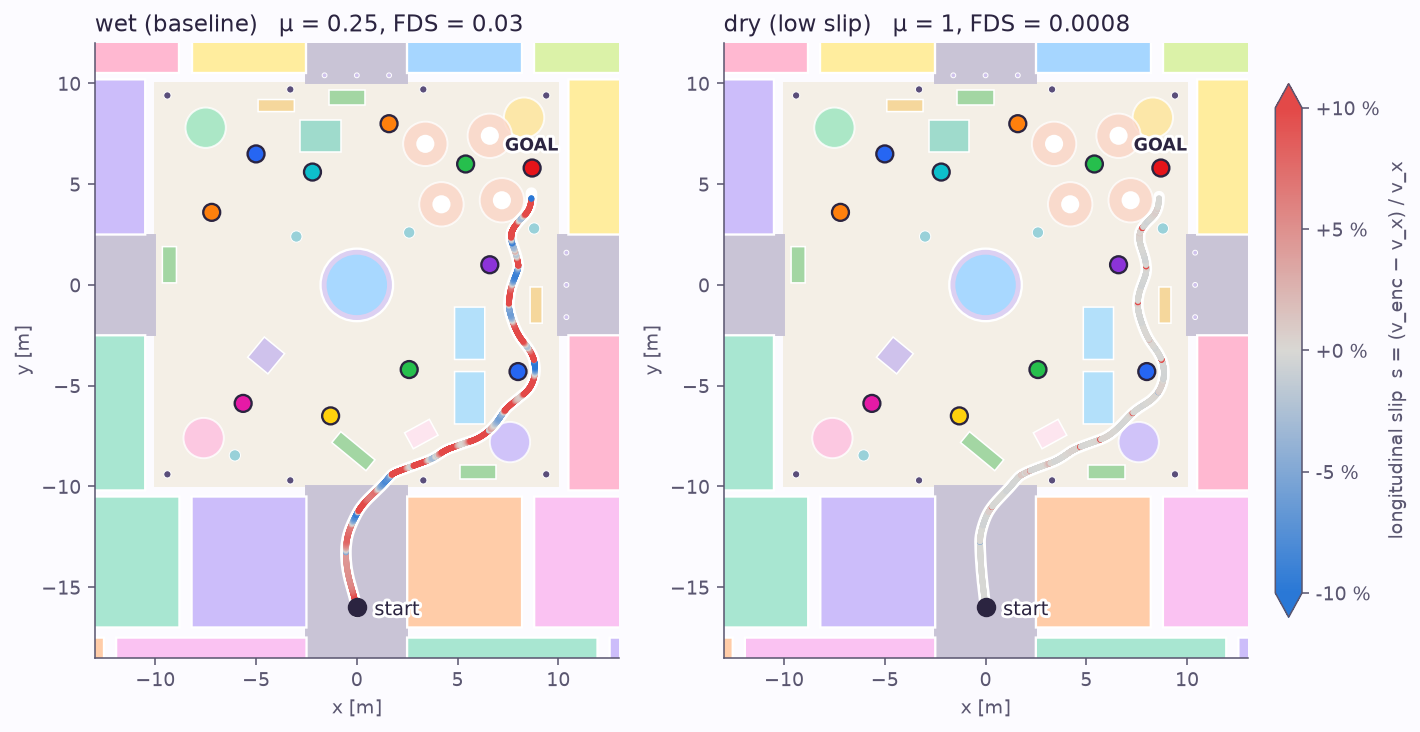

**Q4 (c) - s_long against the distance travelled, wet vs dry**

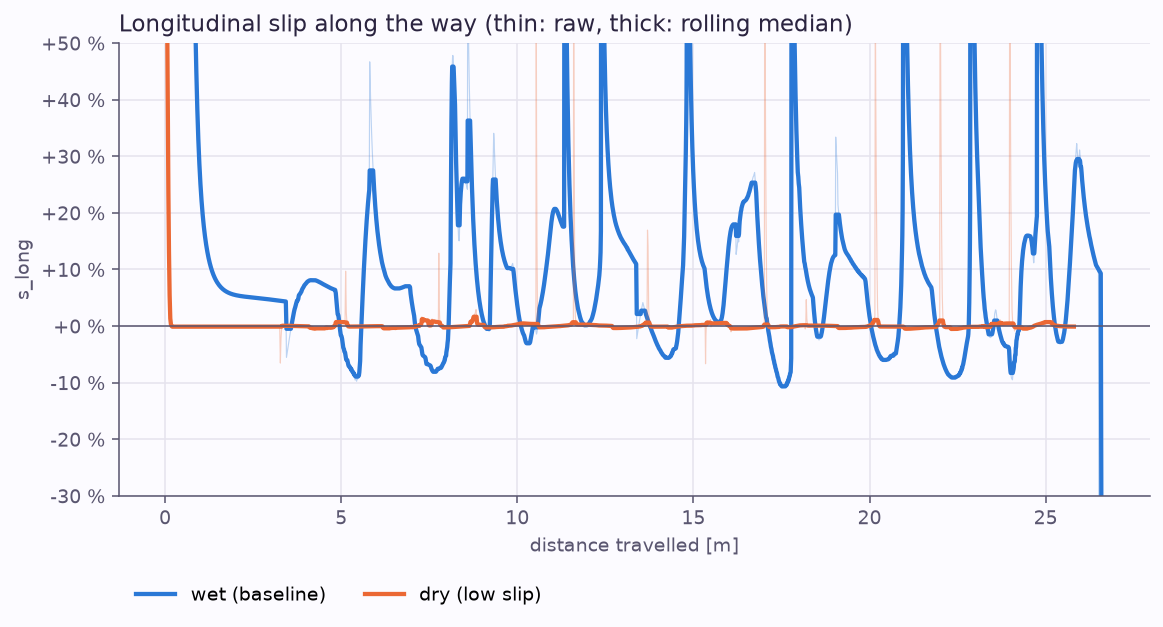

**where the slip comes from: v_enc (encoders) against v_x (ground truth)**

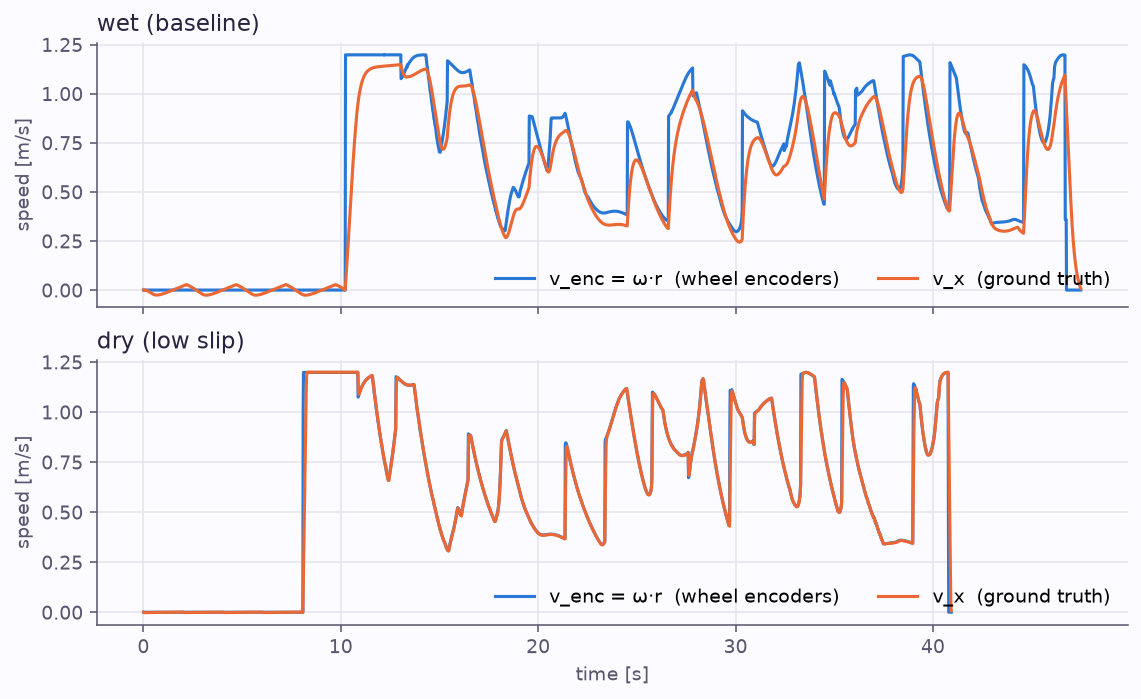

**the camera: solid box = red goal, dashed = decoy, ignored**

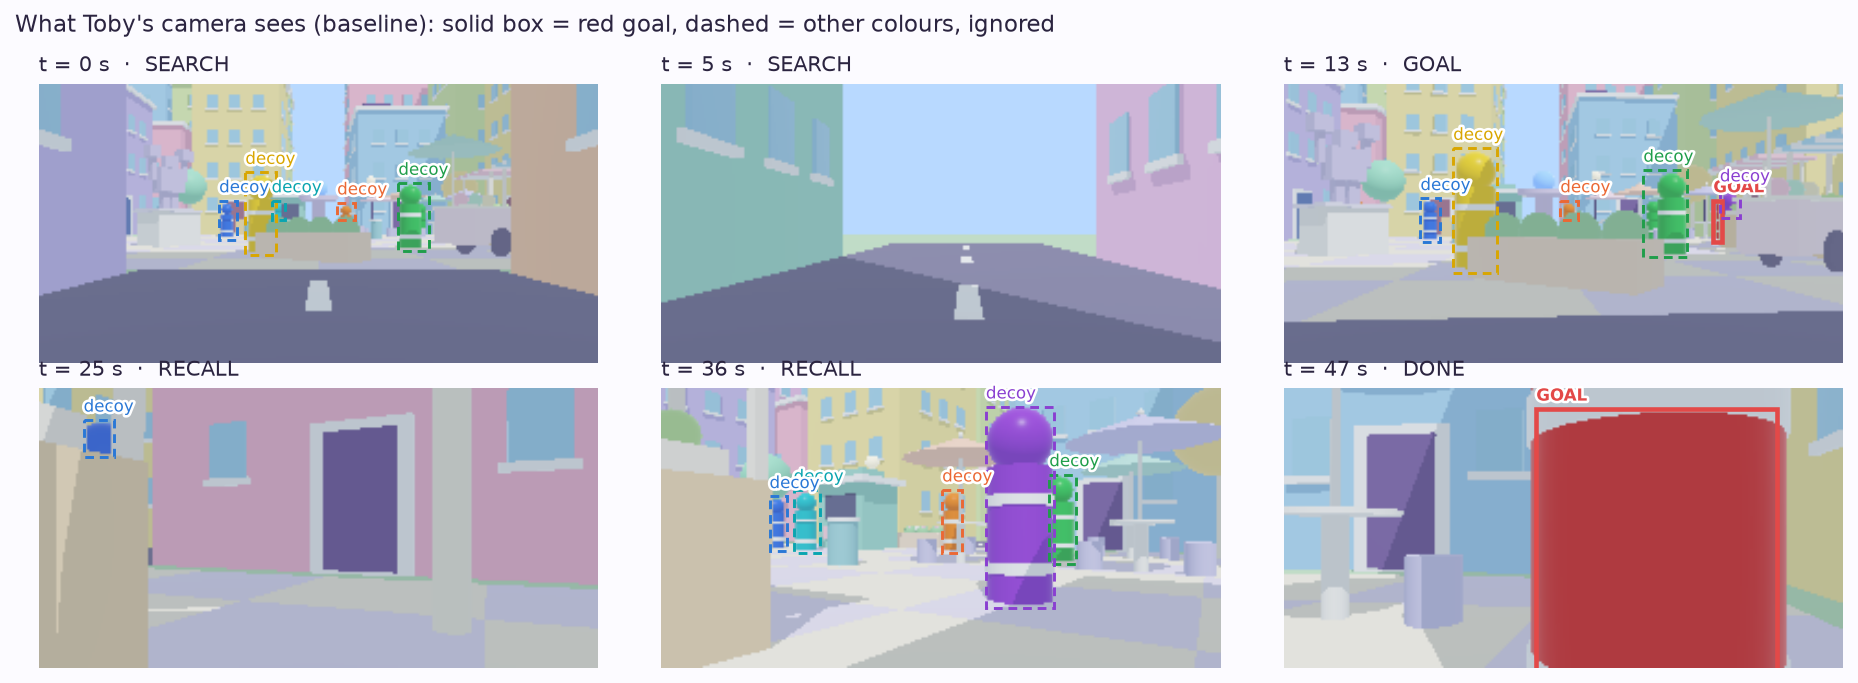

**wet and dry on the same clock: the wet run falls behind**

figures in /home/havard/hand_in/MAS512_Assignment_2/q4-webots/figures 
sensor logs in /home/havard/hand_in/MAS512_Assignment_2/q4-webots/data


In [4]:
import json
import os
import shutil
import subprocess
import sys
import threading
import time
from pathlib import Path

from IPython.display import HTML, Image, Markdown, display

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------
RUN_SIM = True        # False -> keep q4-webots/data/ and only redo the analysis
SHOW_GUI = True       # True -> the Webots window opens and the run is watched in real time
KEEP_OPEN = False     # True -> Webots stays open (paused) at the end, close it by hand
RUN_VIDEOS = True     # the mp4 needs ffmpeg and about a minute
SIM_TIMEOUT = 1800    # [s] per simulation, so a stuck Webots cannot hang the cell

# (a) and (b), the two squares that differ only in the wheel-floor friction.
# Add "no_goal" and "hidden_goal" for the two diagnostic worlds:
# they are dry worlds that check the controller gives up instead of looping for ever.
SIM_RUNS = ["baseline", "low_slip"]

def find_root():
    """q4-webots/, whichever directory the notebook was opened from."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (parent, parent / "q4-webots", parent / "Assignment2" / "q4-webots"):
            if (candidate / "controllers" / "slip_nav" / "slip_nav.py").is_file():
                return candidate
    raise FileNotFoundError("q4-webots/ not found - open this notebook inside the repository")


def find_webots():
    """The Webots executable: on PATH, or wherever the installer put it."""
    known = ["/usr/local/webots/webots", "/snap/bin/webots",
             "/Applications/Webots.app/Contents/MacOS/webots",
             r"C:\Program Files\Webots\msys64\mingw64\bin\webotsw.exe"]
    return (shutil.which("webots") or shutil.which("webotsw")
            or next((p for p in known if Path(p).exists()), None))


def sh(*cmd, env=None, timeout=None):
    """Run a terminal command inside q4-webots/ and stream its output into the cell."""
    print(f"\n$ {' '.join(str(c) for c in cmd)}", flush=True)
    t0 = time.time()
    proc = subprocess.Popen([str(c) for c in cmd], cwd=ROOT, text=True, bufsize=1,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            env={**os.environ, **(env or {})})
    killer = threading.Timer(timeout, proc.kill) if timeout else None   # a hung run must not block the cell
    if killer:
        killer.start()
    try:
        for line in proc.stdout:
            print("  " + line.rstrip(), flush=True)
    finally:
        proc.wait()
        if killer:
            killer.cancel()
    print(f"  [exit {proc.returncode}, {time.time() - t0:.0f} s]", flush=True)
    return proc.returncode


ROOT = find_root()
WEBOTS = find_webots()
print("q4-webots :", ROOT)
print("webots    :", WEBOTS or "NOT FOUND - install Webots R2025a, or set RUN_SIM = False")
print("ffmpeg    :", shutil.which("ffmpeg") or "missing - animate_run.py falls back to a GIF")

# ------------------------------------------------------------
# 3. DEPENDENCIES AND WORLDS
# numpy/pandas/matplotlib for the analysis; the .wbt files are generated by a
# script, never written by hand, so the city is reproducible from source.
# ------------------------------------------------------------
sh(sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt")
sh(sys.executable, "tools/make_worlds.py")

# ------------------------------------------------------------
# 4. THE SIMULATIONS
# ------------------------------------------------------------
gui = ["--mode=realtime"] if SHOW_GUI else ["--mode=fast", "--no-rendering", "--minimize"]
sim_env = {} if (SHOW_GUI and KEEP_OPEN) else {"WEBOTS_AUTOQUIT": "1"}

# On a machine with no screen (a server) Webots needs a virtual X display.
headless_linux = sys.platform.startswith("linux") and not os.environ.get("DISPLAY")
xvfb = ["xvfb-run", "-a"] if (headless_linux and shutil.which("xvfb-run")) else []
if SHOW_GUI and headless_linux:
    print("\nno DISPLAY: this machine has no screen, the window cannot open -> set SHOW_GUI = False")

if RUN_SIM and WEBOTS:
    for run in SIM_RUNS:
        sh(*xvfb, WEBOTS, "--batch", *gui,
           "--stdout", "--stderr", f"worlds/city_{run}.wbt",
           env=sim_env, timeout=SIM_TIMEOUT)
else:
    print("\nsimulations skipped - reusing the runs already in q4-webots/data/")

# ------------------------------------------------------------
# 5. ANALYSIS
# plot_slip prints the slip statistics and writes the three figures of item (c);
# camera_montage redoes the controller's colour detection on the saved frames;
# slide_figures makes the flow chart and the state machine for the presentation.
# ------------------------------------------------------------
sh(sys.executable, "analysis/plot_slip.py", *SIM_RUNS[:2])
sh(sys.executable, "analysis/camera_montage.py", "baseline")
sh(sys.executable, "tools/slide_figures.py")
if RUN_VIDEOS:
    sh(sys.executable, "analysis/animate_run.py", "compare")

# ------------------------------------------------------------
# 6. RESULTS
# The medians come from plot_slip itself, so the table and the figures can never
# disagree: same filter (driving states only, |v_x| > 0.1 m/s), same data.
# ------------------------------------------------------------
sys.path.insert(0, str(ROOT / "analysis"))
from plot_slip import friction, load  # noqa: E402

LABEL = {"baseline": "(a) wet square", "low_slip": "(b) dry square"}
rows = []
for run in ("baseline", "low_slip"):
    d, meta = load(run)
    mu, fds = friction(meta)
    s = d["s"].dropna()
    rows.append(f"| {LABEL.get(run, run)} | {mu:g} | {fds:g} | {meta['result']} | "
                f"{meta['duration_s']:.1f} s | {d['dist'].iloc[-1]:.1f} m | "
                f"**{100 * s.median():+.1f} %** | {len(meta['decoys_ignored'])} |")

display(Markdown(
    "### Q4 (a) (b) - the same mission on two frictions\n\n"
    "| run | μ wheel-floor | force dependent slip | outcome | time | path | median s_long | decoy colours ignored |\n"
    "|---|---|---|---|---|---|---|---|\n" + "\n".join(rows) +
    "\n\nThe red beacon is not visible from the start and there are ten decoys: Toby has to "
    "search for it, recognise the colour and ignore the others. On the wet square the wheels "
    "turn faster than the robot advances, on the dry one the two velocities coincide."))

for name, caption in [
    ("slip_map.png", "Q4 (c) - the toy city from above, trajectory coloured by s_long"),
    ("slip_profile.png", "Q4 (c) - s_long against the distance travelled, wet vs dry"),
    ("speeds.png", "where the slip comes from: v_enc (encoders) against v_x (ground truth)"),
    ("what_toby_sees.png", "the camera: solid box = red goal, dashed = decoy, ignored"),
]:
    display(Markdown(f"**{caption}**"))
    display(Image(filename=str(ROOT / "figures" / name)))

for name in ("run_compare.mp4", "run_compare.gif"):
    path = ROOT / "figures" / name
    if path.exists():
        src = os.path.relpath(path, Path.cwd()).replace(os.sep, "/")
        display(Markdown("**wet and dry on the same clock: the wet run falls behind**"))
        display(HTML(f'<video src="{src}" controls loop width="900"></video>' if path.suffix == ".mp4"
                     else f'<img src="{src}" width="900">'))
        break

print("figures in", ROOT / "figures", "\nsensor logs in", ROOT / "data")